# Practical 6: Logistic Regression (Confusion Matrix, Precision, Recall, F1)

**Aim:** Build a binary classifier with logistic regression and judge it with the confusion matrix, precision, recall and F1-score.

**Dataset:** Breast Cancer (569 patients, 30 features). Built into scikit-learn.

> **Note on labels:** in scikit-learn 0 = malignant and 1 = benign. For a cancer test the "positive" class should be **malignant**, so we flip the labels: **1 = malignant (positive), 0 = benign (negative)**. Then *recall* means "how many real cancers did we find?".

**Steps:** 1) Load  2) Split and scale  3) Train  4) Confusion matrix  5) Metrics  6) ROC curve  7) Threshold  8) Sigmoid

## Step 1: Load the data

Benign: 357  Malignant: 212


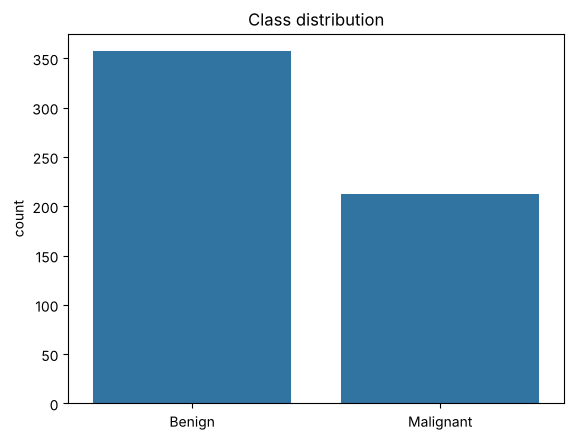

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score)

data = load_breast_cancer()
X = data.data
y = 1 - data.target          # flip: 1 = malignant (positive), 0 = benign (negative)

print("Benign:", (y == 0).sum(), " Malignant:", (y == 1).sum())

sns.countplot(x=y)
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.title("Class distribution")
plt.show()

**How to read:** the bars show how many patients are in each class. About 63% are benign and 37% malignant: a little imbalanced, so accuracy alone can mislead and we also use precision, recall and F1.

## Step 2: Split and scale

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Step 3: Train the model
Logistic regression gives a **probability** between 0 and 1 using the sigmoid function. If the probability is 0.5 or more, it predicts class 1 (malignant).

In [3]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)                 # class: 0 or 1
y_prob = model.predict_proba(X_test)[:, 1]     # probability of malignant

print("First 5 probabilities:", y_prob[:5].round(3))
print("First 5 predictions  :", y_pred[:5])
print("First 5 actual       :", y_test[:5])

First 5 probabilities: [0.    1.    0.043 0.576 0.509]
First 5 predictions  : [0 1 0 1 1]
First 5 actual       : [0 1 0 1 0]


## Step 4: Confusion matrix

TN = 71  FP = 1  FN = 3  TP = 39


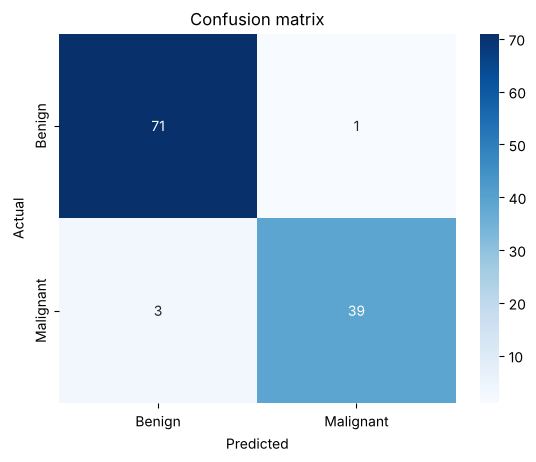

In [4]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

**How to read:** rows = actual, columns = predicted (positive = malignant).

| | Predicted benign | Predicted malignant |
|---|---|---|
| **Actual benign** | TN (correct) | FP (false alarm) |
| **Actual malignant** | FN (missed cancer) | TP (correct) |

The diagonal is correct predictions; the other two cells are mistakes. The most dangerous mistake is **FN**: a cancer predicted as benign.

## Step 5: Metrics
- **Accuracy** = (TP + TN) / all
- **Precision** = TP / (TP + FP): of those we called malignant, how many really were?
- **Recall** = TP / (TP + FN): of all real cancers, how many did we find?
- **F1** = balance of precision and recall

In [5]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))

# Check by hand using the confusion matrix numbers
print("Precision by hand:", round(tp / (tp + fp), 4))
print("Recall by hand   :", round(tp / (tp + fn), 4))

print()
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Accuracy : 0.9649
Precision: 0.975
Recall   : 0.9286
F1-score : 0.9512
Precision by hand: 0.975
Recall by hand   : 0.9286

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## Step 6: ROC curve

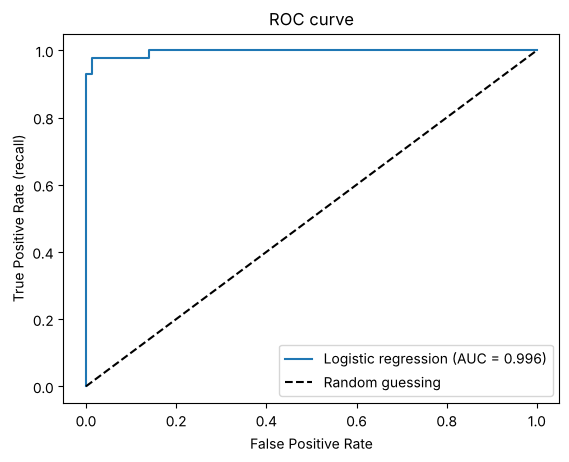

In [6]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label="Logistic regression (AUC = " + str(round(auc, 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (recall)")
plt.title("ROC curve")
plt.legend()
plt.show()

**How to read:** the curve shows recall (up) against false alarms (right) for every possible threshold. A curve close to the **top-left corner** is best; the dashed diagonal is random guessing. **AUC** is the area under the curve: 1.0 is perfect, 0.5 is random. Ours is close to 1.

## Step 7: Changing the threshold
Lowering the threshold means we call more patients malignant: **recall goes up, precision goes down**.

In [7]:
for t in [0.3, 0.5, 0.7]:
    pred = (y_prob >= t).astype(int)
    print("Threshold", t,
          "| Precision:", round(precision_score(y_test, pred), 3),
          "| Recall:", round(recall_score(y_test, pred), 3),
          "| Missed cancers (FN):", ((pred == 0) & (y_test == 1)).sum())

Threshold 0.3 | Precision: 0.976 | Recall: 0.976 | Missed cancers (FN): 1
Threshold 0.5 | Precision: 0.975 | Recall: 0.929 | Missed cancers (FN): 3
Threshold 0.7 | Precision: 1.0 | Recall: 0.905 | Missed cancers (FN): 4


For cancer screening we prefer a **lower threshold** (higher recall): a false alarm is checked with another test, but a missed cancer can be fatal.

## Step 8: The sigmoid function

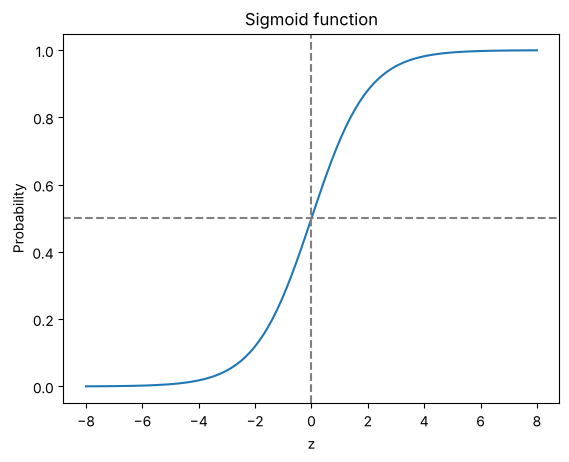

In [8]:
z = np.linspace(-8, 8, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("z")
plt.ylabel("Probability")
plt.title("Sigmoid function")
plt.show()

**How to read:** an S-shaped curve that turns any number `z` into a probability between 0 and 1. It crosses 0.5 at z = 0: that is the **decision boundary**.

## Conclusion
Logistic regression separated malignant from benign tumours with high accuracy, precision, recall and F1, and an AUC close to 1. The confusion matrix shows exactly which mistakes happen (FP and FN), and the threshold can be changed to trade precision against recall. For screening, recall is the most important metric.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is logistic regression? Is it regression or classification?**
Despite the name, it is a classification algorithm. It models the probability that an input belongs to class 1 using the sigmoid function and then applies a threshold (default 0.5).

**Q2. Why not use linear regression for classification?**
Linear regression outputs values outside 0 to 1, is sensitive to outliers, and its squared-error loss is not suited to categories. Logistic regression gives valid probabilities.

**Q3. What is the sigmoid function?**
$\sigma(z) = 1/(1+e^{-z})$. It squashes any real number into (0, 1), with $\sigma(0)=0.5$.

**Q4. What loss function does logistic regression use?**
Log loss (binary cross-entropy): $-[y\log p + (1-y)\log(1-p)]$, minimised with gradient descent or solvers such as lbfgs.

**Q5. What is the decision boundary?**
The surface where the predicted probability equals the threshold (0.5), i.e., where $z=0$. It is linear in logistic regression.

**Q6. What are odds and log-odds?**
Odds = $p/(1-p)$. Log-odds (logit) = $\log(p/(1-p)) = z$, a linear combination of the features. Each coefficient is the change in log-odds for a one-unit change in that feature; $e^{b}$ is the odds ratio.

**Q7. What is a confusion matrix?**
A table comparing actual and predicted classes: TP, TN, FP and FN counts.

**Q8. Define TP, TN, FP, FN.**
TP: predicted positive and actually positive. TN: predicted negative and actually negative. FP: predicted positive but actually negative (false alarm, Type I). FN: predicted negative but actually positive (missed case, Type II).

**Q9. Define accuracy, precision, recall and F1.**
Accuracy: share of all predictions that are correct. Precision: of predicted positives, how many are truly positive. Recall (sensitivity): of actual positives, how many were found. F1: harmonic mean of precision and recall.

**Q10. Why is accuracy not enough?**
With imbalanced classes a model that always predicts the majority class can have high accuracy but be useless. Precision, recall and F1 expose this.

**Q11. When do you prefer high precision and when high recall?**
High recall when missing a positive is costly (cancer screening, fraud). High precision when a false alarm is costly (spam filter blocking real mail, legal decisions).

**Q12. Why is F1 the harmonic mean and not the arithmetic mean?**
The harmonic mean is dominated by the lower value, so a model cannot get a high F1 by being excellent at one metric and terrible at the other.

**Q13. How does changing the threshold affect results?**
Lower threshold: more positives, recall up, precision down. Higher threshold: precision up, recall down.

**Q14. What is specificity?**
$TN/(TN+FP)$: the share of actual negatives correctly identified (true negative rate).

**Q15. What is the ROC curve and AUC?**
ROC plots TPR against FPR at all thresholds. AUC is the area under it: 1.0 is perfect, 0.5 is random. It equals the probability that a random positive is ranked above a random negative.

**Q16. ROC curve vs precision-recall curve: when to use which?**
Use PR curves for heavily imbalanced data because ROC can look optimistic when negatives dominate.

**Q17. What is the role of the regularisation parameter C?**
C is the inverse of regularisation strength. Small C means stronger regularisation (simpler model, less overfitting); large C means weaker regularisation. By default scikit-learn applies L2 regularisation.

**Q18. Can logistic regression do multiclass classification?**
Yes, using One-vs-Rest or the softmax (multinomial) approach.

**Q19. What are the assumptions of logistic regression?**
Binary (or categorical) target, independent observations, little multicollinearity, a linear relationship between features and the log-odds, and a reasonably large sample size.

**Q20. Why is `stratify=y` used?**
It keeps the same class proportions in the train and test sets, which matters for imbalanced data.

**Q21. Why did you scale the features?**
Logistic regression is solved by gradient-based optimisation and regularised; scaling speeds up convergence and makes coefficients comparable.

**Q22. What is Type I and Type II error?**
Type I = false positive (false alarm). Type II = false negative (missed detection).

**Q23. What are macro, micro and weighted averages?**
Macro: simple mean of per-class scores. Weighted: mean weighted by class support. Micro: computed globally from total TP, FP, FN (equals accuracy for single-label multiclass).

**Q24. Is logistic regression affected by outliers?**
Less than linear regression, but extreme values can still distort the fit; scaling and outlier handling help.

**Q25. Why did you treat malignant as the positive class?**
In screening, the event we want to detect is the disease. Treating it as positive means recall measures how many cancers we catch and FN is the dangerous error. (In scikit-learn's raw labels, 1 is benign, so the labels were flipped.)

## B. Questions about the graphs

**G1. How do you read the confusion matrix heatmap?**
Rows are actual classes and columns are predicted classes. The diagonal shows correct predictions; off-diagonal cells are mistakes. A dark diagonal and light off-diagonal means a good model.

**G2. Which cell is the most dangerous here?**
False Negative (bottom-left): a malignant tumour predicted as benign, so the patient is missed.

**G4. What does the ROC curve show?**
The trade-off between true positive rate (y) and false positive rate (x) at all thresholds. A curve near the top-left is best; the diagonal is random guessing.

**G5. What is AUC?**
Area Under the ROC Curve. 1.0 is perfect, 0.5 is random.

**G6. What does the sigmoid curve look like?**
An S-shape from 0 to 1 crossing 0.5 at z = 0. It turns any real number into a probability.

**G10. What does the class distribution bar chart tell you?**
Whether the classes are balanced. Here the data is mildly imbalanced (about 63% benign), so accuracy alone is not enough.

## C. Code questions

**C1. What is the difference between `predict` and `predict_proba`?**
`predict` returns class labels (using the 0.5 threshold). `predict_proba` returns the probability of each class.

**C2. Why `predict_proba(X)[:, 1]`?**
It selects the column with the probability of the positive class (class 1).

**C3. What does `confusion_matrix(y_true, y_pred).ravel()` return?**
The four counts in the order TN, FP, FN, TP (for labels 0 and 1).

**C4. Why `max_iter=1000`?**
The solver may need more iterations than the default (100) to converge.

**C5. Why is the scaler fitted only on training data?**
To avoid data leakage from the test set.

**C6. What does `zero_division=0` do?**
Returns 0 instead of a warning/error when a precision denominator is zero (no predicted positives).